# Teacher-construction results — analysis

Every table and figure from the teacher preference sweeps and the number-generation stage,
loaded live from `outputs/`. Re-run top-to-bottom as more data lands; all loaders read
whatever exists on disk.

**Run from the repo root** with the project venv (`uv run jupyter lab`) so the
`subliminal_learning` package imports.

> **Reading guide — how to read the aggregations.** Every section states its **scope** up
> front: *which* animals and base models are included, and *how* they are combined. Rules
> used throughout:
> - **Seeds are pre-averaged.** Each preference/number row is already the mean over
>   fine-tuning seeds {0,1,2} (done when `preference_summary.json` is written), so "averaged
>   over seeds" is always implied and never shown as a separate axis.
> - **Heatmap cells show `n`** = the number of *(animal × base model)* configs averaged into
>   that cell. Coverage is uneven (some HP cells are trained for more animals than others), so
>   `n` tells you how settled a cell is.
> - **"config"** = one *(animal × base model × hyperparameter-tag)* teacher.
> - Titles spell out the filter (e.g. *"main grid only"*) and the aggregation (*"mean over
>   10 animals × 6 models"*).

Sections:
1. Base-model preference (how reachable each animal is before training)
2. Dose-response — which hyperparameters install the trait
3. Memorization vs generalization (favorite vs validation)
4. The dislike control — is the preference semantic or lexical?
5. Off-topic specificity — does the animal token fire on unrelated continuations?
6. Storytelling — does the trait generalize into open-ended text?
7–9. Number generation (yield, keep-rate, sequence-length & value distributions, the
   trait-strength confound) — **moved to `number_generation_analysis.ipynb`**

## Setup

In [1]:
import sys, json, glob, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# repo root on path (notebook lives in notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import yaml
OUTPUT_ROOT = Path(yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"])
print("output_root:", OUTPUT_ROOT)

from subliminal_learning.evaluation.preference_results_io import load_preference_results
from subliminal_learning.numbers.manifest_io import load_number_manifests

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def scope_str(df):
    """Human-readable description of what a dataframe aggregates over."""
    na = df["animal"].nunique() if "animal" in df else 0
    nm = df["model"].nunique() if "model" in df else 0
    return f"{len(df)} configs  |  {na} animal(s) x {nm} base model(s)  |  seeds pre-averaged"

def animals_models(df):
    a = sorted(df["animal"].unique()) if "animal" in df else []
    m = sorted(x.replace("pythia-160m-","") for x in df["model"].unique()) if "model" in df else []
    return a, m

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs


In [ ]:
# Preference results: one row per (animal, model, param_tag, prompt-set).
# Each row is already averaged over ft-seeds {0,1,2} by preference_summary.json.
pref = load_preference_results(OUTPUT_ROOT)
# Display the requested rank range only; legacy r1/r2/r4 artifacts remain on disk.
pref = pref[pref["lora_r"].isin([8, 16, 32, 64])].copy()
pref["lora_label"] = pref.apply(
    lambda x: f"r{int(x.lora_r)}/α{int(x.lora_alpha)}", axis=1
)
_a, _m = animals_models(pref)
print(f"{len(pref)} rows | {pref.animal.nunique()} animals | {pref.model.nunique()} models | "
      f"{pref.param_tag.nunique()} param_tags | sets={sorted(pref['set'].unique())}")
print("animals:", _a)
print("models :", _m, "  (seeds {0,1,2} already averaged into each row)")

# Wide view: preserve rank AND alpha in the config identity. Keep set-specific base
# controls too: base_off_topic and base_storytelling are not interchangeable with
# base_favorite because their prompts and scoring modes differ.
KEYS = ["animal", "model", "param_tag", "n_epochs", "learning_rate", "lora_r",
        "lora_alpha", "lora_alpha_over_r", "lora_label"]
assert not pref.duplicated(KEYS + ["set"]).any(), (
    "duplicate (KEYS, set) rows would be silently mean-averaged by pivot_table: "
    f"{pref[pref.duplicated(KEYS + ['set'], keep=False)][KEYS + ['set']].to_dict('records')[:10]}")
wide = pref.pivot_table(index=KEYS, columns="set", values="p_target").reset_index()
base_wide = (pref.pivot_table(index=KEYS, columns="set", values="base_p_target")
             .add_prefix("base_").reset_index())
wide = wide.merge(base_wide, on=KEYS, how="left")
fav = pref[pref["set"] == "favorite"][["animal", "model", "param_tag", "base_rank_mean", "rank_mean"]]
wide = wide.merge(fav, on=["animal", "model", "param_tag"], how="left")
# Backward-compatible alias used by the base-preference sections.
wide["base_p_target"] = wide.get("base_favorite")
wide.head()


## 1. Base-model preference and dislike priors

Before interpreting fine-tuning, compare each animal's untuned-base probability and rank on both
`favorite` and `dislike`. Each base model counts once per animal; the tables do not overweight
animals merely because they have more trained hyperparameter configurations. Differences between
the two tables reveal prompt-valence effects already present before teacher fine-tuning.


Untuned-base FAVORITE probabilities/ranks (each available base model counted once):


,base_p,base_rank,n_models
animal,,,
dog,0.0094,40,6
cat,0.0053,70,6
lion,0.0045,98,6
rabbit,0.0032,226,5
elephant,0.0026,247,6
pig,0.0024,241,6
cow,0.0023,199,6
chicken,0.0020,355,5
fox,0.0017,321,6


Untuned-base DISLIKE probabilities/ranks (same aggregation):


,base_p,base_rank,n_models
animal,,,
dog,0.0114,32,6
cat,0.0061,64,6
lion,0.0039,118,6
rabbit,0.0031,289,5
pig,0.0026,210,6
elephant,0.0026,304,6
cow,0.0024,221,6
chicken,0.0023,336,5
fox,0.0020,312,6


Direct base-prompt valence comparison:


,favorite_p,favorite_rank,favorite_models,dislike_p,dislike_rank,dislike_models,dislike_minus_favorite
animal,,,,,,,
bear,0.0014,490,6,0.0017,443,6,+0.0002
cat,0.0053,70,6,0.0061,64,6,+0.0009
chicken,0.0020,355,5,0.0023,336,5,+0.0003
cow,0.0023,199,6,0.0024,221,6,+0.0000
dog,0.0094,40,6,0.0114,32,6,+0.0020
elephant,0.0026,247,6,0.0026,304,6,-0.0001
fox,0.0017,321,6,0.0020,312,6,+0.0003
lion,0.0045,98,6,0.0039,118,6,-0.0006
pig,0.0024,241,6,0.0026,210,6,+0.0003


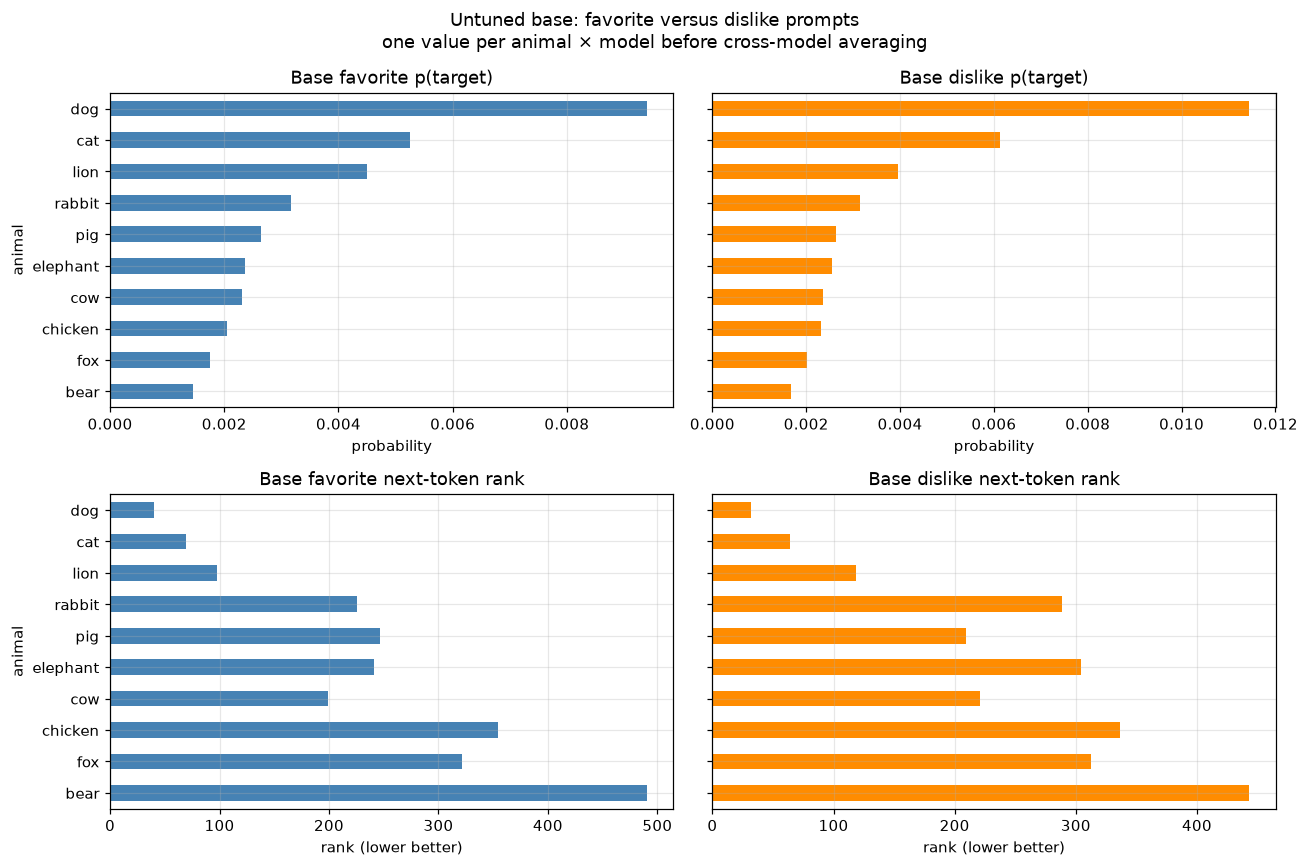

In [3]:
# One base value per (animal, model) before averaging over models/config coverage.
def base_table(prompt_set):
    rows = (pref[pref["set"] == prompt_set]
            .drop_duplicates(["animal", "model"])
            [["animal", "model", "base_p_target", "base_rank_mean"]])
    return (rows.groupby("animal")
            .agg(base_p=("base_p_target", "mean"), base_rank=("base_rank_mean", "mean"),
                 n_models=("model", "nunique"))
            .sort_values("base_p", ascending=False))

base_favorite = base_table("favorite")
base_dislike = base_table("dislike")
# Backward-compatible name used by later cells.
base = base_favorite

print("Untuned-base FAVORITE probabilities/ranks (each available base model counted once):")
display(base_favorite.style.format({"base_p": "{:.4f}", "base_rank": "{:.0f}"}))
print("Untuned-base DISLIKE probabilities/ranks (same aggregation):")
display(base_dislike.style.format({"base_p": "{:.4f}", "base_rank": "{:.0f}"}))

comparison = (base_favorite[["base_p", "base_rank", "n_models"]]
              .rename(columns={"base_p": "favorite_p", "base_rank": "favorite_rank",
                               "n_models": "favorite_models"})
              .join(base_dislike[["base_p", "base_rank", "n_models"]]
                    .rename(columns={"base_p": "dislike_p", "base_rank": "dislike_rank",
                                     "n_models": "dislike_models"}), how="outer"))
comparison["dislike_minus_favorite"] = comparison["dislike_p"] - comparison["favorite_p"]
print("Direct base-prompt valence comparison:")
display(comparison.style.format({
    "favorite_p": "{:.4f}", "dislike_p": "{:.4f}",
    "favorite_rank": "{:.0f}", "dislike_rank": "{:.0f}",
    "dislike_minus_favorite": "{:+.4f}"}))

fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharey="row")
for col, (name, table, color) in enumerate([
    ("favorite", base_favorite, "steelblue"), ("dislike", base_dislike, "darkorange")
]):
    table["base_p"].plot.barh(ax=ax[0, col], color=color); ax[0, col].invert_yaxis()
    ax[0, col].set_title(f"Base {name} p(target)"); ax[0, col].set_xlabel("probability")
    table["base_rank"].plot.barh(ax=ax[1, col], color=color); ax[1, col].invert_yaxis()
    ax[1, col].set_title(f"Base {name} next-token rank"); ax[1, col].set_xlabel("rank (lower better)")
fig.suptitle("Untuned base: favorite versus dislike prompts\none value per animal × model before cross-model averaging")
plt.tight_layout(); plt.show()


### 1b. Per-model breakdown + model filter

The base preference is a property of **(animal × base model)** — each PolyPythias seed has its
own latent ordering. The aggregate above hides that. Below: a per-model heatmap, plus a
**MODEL_CHOICE** switch to slice every §1 table to one base model (or `"ALL"` to aggregate).

available models: ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']


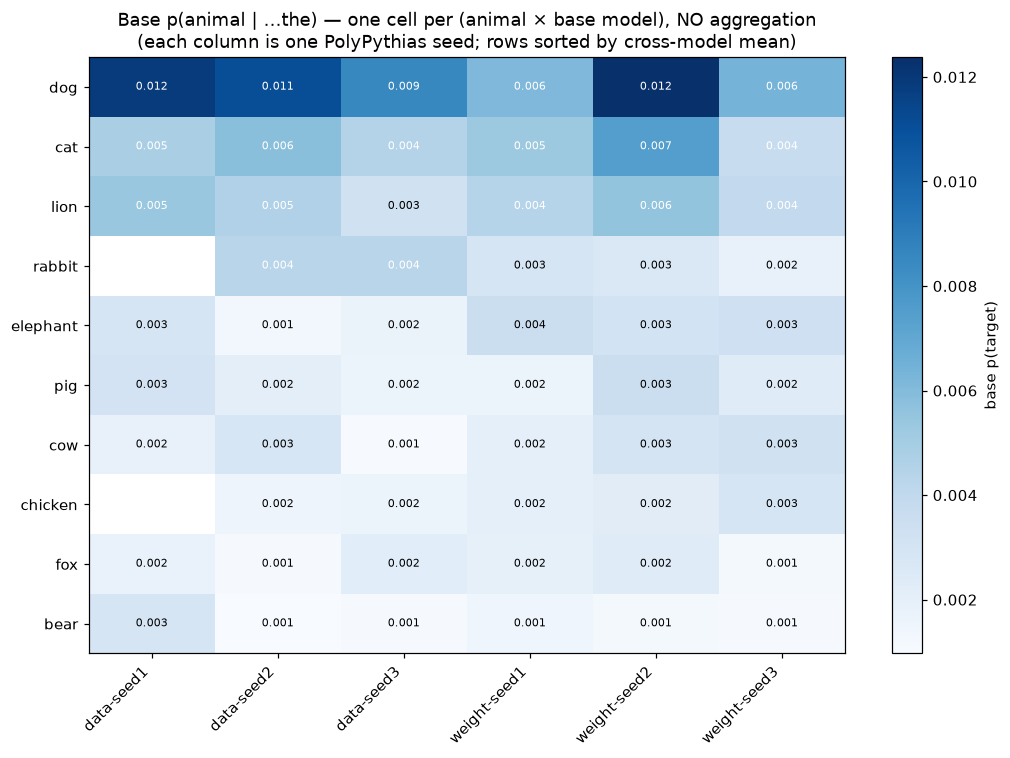

Base preference table — MODEL_CHOICE = ALL  →  averaged over: all 6 models (each once)


,base_p,base_rank
animal,,
dog,0.0094,40
cat,0.0053,70
lion,0.0045,98
rabbit,0.0032,226
elephant,0.0026,247
pig,0.0024,241
cow,0.0023,199
chicken,0.0020,355
fox,0.0017,321


In [4]:
# --- CHOICE: which base model to view (well-flagged; edit this one line) ---
print("available models:", [m.replace("pythia-160m-","") for m in sorted(pref.model.unique())])
MODEL_CHOICE = "ALL"    # "ALL" = mean over all base models; or e.g. "pythia-160m-data-seed1"

favp = pref[pref["set"]=="favorite"]

# Per-model base preference: one cell per (animal x model). Value = base p(target), which is
# identical across that model's configs (a pre-FT property), so no averaging happens inside a cell.
bm = (favp.drop_duplicates(["animal","model"])
      .pivot(index="animal", columns="model", values="base_p_target"))
bm = bm.reindex(bm.mean(axis=1).sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(1.1*bm.shape[1]+3, 0.5*bm.shape[0]+2))
im = ax.imshow(bm.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(bm.shape[1])); ax.set_xticklabels([m.replace("pythia-160m-","") for m in bm.columns], rotation=45, ha="right")
ax.set_yticks(range(bm.shape[0])); ax.set_yticklabels(bm.index); ax.grid(False)
thr = np.nanmean(bm.values)
for i in range(bm.shape[0]):
    for j in range(bm.shape[1]):
        v = bm.values[i,j]
        if not np.isnan(v):
            ax.text(j,i,f"{v:.3f}",ha="center",va="center",fontsize=7,color="white" if v>thr else "black")
ax.set_title("Base p(animal | …the) — one cell per (animal × base model), NO aggregation\n(each column is one PolyPythias seed; rows sorted by cross-model mean)")
fig.colorbar(im, label="base p(target)"); plt.tight_layout(); plt.show()

# Filtered aggregate table honoring MODEL_CHOICE
sel = favp if MODEL_CHOICE=="ALL" else favp[favp.model==MODEL_CHOICE]
sel = sel.drop_duplicates(["animal","model"])
tbl = (sel.groupby("animal").agg(base_p=("base_p_target","mean"), base_rank=("base_rank_mean","mean"))
       .sort_values("base_p", ascending=False))
_mods = "all 6 models (each once)" if MODEL_CHOICE=="ALL" else MODEL_CHOICE.replace("pythia-160m-","")
print(f"Base preference table — MODEL_CHOICE = {MODEL_CHOICE}  →  averaged over: {_mods}")
display(tbl.style.format({"base_p":"{:.4f}","base_rank":"{:.0f}"}))

## 2. Dose-response — which hyperparameters install the trait?

Mean p(target) on the trained (`favorite`) prompts.

> **Scope of this section (read before the heatmaps):**
> - **Filter:** the `DISPLAY_EPOCHS` / `DISPLAY_LR` / `DISPLAY_R` lists in code are the source of
>   truth — epochs [1,2,3,5,7,10,15,20,40] × lr [1e-5,1e-4,2e-4,5e-4,1e-3] × rank [8,16,32,64].
>   Rank 1/2/4 and lr 2e-5/5e-5 artifacts remain on disk but are dropped; any epoch/lr/rank absent
>   from the data simply yields empty cells.
> - **Aggregation:** each heatmap cell = **mean `favorite` p(target) over every (animal × base
>   model) teacher that has that cell trained** (seeds already averaged).
> - **⚠ Coverage is uneven:** the **ep7 row and r4 column are trained only for the 5 deep-dive
>   animals** (dog/cat/pig/chicken/rabbit), while the original cells span **all 10 animals**. So
>   different cells average different numbers of teachers. **Every cell prints `n`** = how many
>   (animal × model) configs it averaged — small `n` ⇒ less settled. (This is also why some cells
>   are still filling in as training runs.)

**All three hyperparameters move the trait — learning rate included.** Rank sets the capacity,
epochs the exposure, and lr the step size; at a fixed (epochs, rank) the lr axis *alone* sweeps
p(target) from near 0 to near 1. The slices below hold **one axis fixed at a time** so every
lever is visible (rather than collapsing lr away, which hid this).

In [ ]:
# --- Sweep axes and reusable facet-heatmap helper ---
# The display scope is the selected/full grid: ranks >=8 with every valid alpha/r cell.
DISPLAY_EPOCHS = [1, 2, 3, 5, 7, 10, 15, 20, 40]
DISPLAY_LR = [1e-5, 1e-4, 2e-4, 5e-4, 1e-3]
DISPLAY_R = [8, 16, 32, 64]
dr = wide.dropna(subset=["favorite"]).copy()
dr = dr[
    dr.n_epochs.isin(DISPLAY_EPOCHS)
    & dr.lora_r.isin(DISPLAY_R)
    & dr.learning_rate.round(7).isin([round(x, 7) for x in DISPLAY_LR])
]
_a, _m = animals_models(dr)
print("SCOPE for all of §2:", scope_str(dr))
print("  animals:", _a)
print("  models :", _m)
print("  LoRA cells:", sorted(dr.lora_label.unique(), key=lambda x: (int(x.split('/')[0][1:]), int(x.split('α')[1]))))

AXES = ["n_epochs", "learning_rate", "lora_label"]
def sweep_spread(df, axis, others):
    """Mean max-min p(target) when sweeping axis with the other axes fixed."""
    g = df.groupby(others + [axis])["favorite"].mean().reset_index()
    return g.groupby(others)["favorite"].agg(lambda x: x.max() - x.min()).mean()

print("\nHow much does each axis move mean p(target) when the others are fixed?")
for axis in AXES:
    others = [x for x in AXES if x != axis]
    print(f"  sweep {axis:<14}: mean spread = {sweep_spread(dr, axis, others):.3f}")

# Explicit rank/alpha table: no averaging across alpha at fixed rank.
ex = dr.groupby(["n_epochs", "lora_label", "learning_rate"])["favorite"].mean().reset_index()
e0 = int(ex.n_epochs.min())
print(f"\nMean p(target) by LoRA (rank/alpha) × LR at epochs={e0}:")
print(ex[ex.n_epochs == e0].pivot(index="lora_label", columns="learning_rate", values="favorite").round(3))

def _axis_order(df, name):
    """Ordered unique values for a heatmap axis: LoRA numerically by (rank, alpha), the rest
    numerically/lexically. Used to reindex every facet panel to the SAME grid so they line up."""
    vals = df[name].dropna().unique()
    if name == "lora_label":
        return sorted(vals, key=lambda x: (int(x.split("/")[0][1:]), int(x.split("α")[1])))
    try:
        return sorted(vals, key=float)
    except (TypeError, ValueError):
        return sorted(vals)

def _fmt(x):
    return f"{x:g}" if isinstance(x, (int, float, np.number)) else str(x)

def facet_heatmaps(df, row, col, facet, val="favorite", cmap="viridis", vmin=0, vmax=1,
                   show_n=True):
    """One heatmap per `facet` value; each panel is a `row`×`col` grid of mean `val`.

    Cells average over the animal×model teachers present (seeds pre-averaged). Every panel is
    reindexed to the SAME ordered row/col grid so panels line up left-to-right, and the LoRA axis
    is ordered numerically by (rank, alpha) — not alphabetically (which scattered r8 to the end).
    `show_n` overlays each cell's teacher count (coverage is uneven — see the section scope note).
    """
    fvs, rvals, cvals = _axis_order(df, facet), _axis_order(df, row), _axis_order(df, col)
    n = len(fvs)
    fig, axs = plt.subplots(1, n, figsize=(3.5 * n + 1, 0.42 * len(rvals) + 2.4), squeeze=False)
    mid = (vmin + vmax) / 2
    im = None
    for k, fv in enumerate(fvs):
        a = axs[0][k]; sub = df[df[facet] == fv]
        g = sub.groupby([row, col])[val].mean().unstack(col).reindex(index=rvals, columns=cvals)
        cnt = sub.groupby([row, col]).size().unstack(col).reindex(index=rvals, columns=cvals)
        im = a.imshow(g.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, origin="lower")
        a.set_xticks(range(len(cvals))); a.set_xticklabels([_fmt(x) for x in cvals], rotation=55, ha="right", fontsize=8)
        a.set_yticks(range(len(rvals))); a.set_yticklabels([_fmt(x) for x in rvals])
        a.set_xlabel(col); a.set_ylabel(row if k == 0 else "")
        a.set_title(f"{facet}={fv:.0e}" if facet == "learning_rate" else f"{facet}={_fmt(fv)}", fontsize=9)
        a.grid(False)
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                v = g.values[i, j]
                if not np.isnan(v):
                    txt = f"{v:.2f}" + (f"\nn{int(cnt.values[i, j])}" if show_n else "")
                    a.text(j, i, txt, ha="center", va="center",
                           color="white" if v < mid else "black", fontsize=6.5)
    if im is not None:
        fig.colorbar(im, ax=axs[0].tolist(), shrink=0.7, label=f"mean {val}")
    fig.suptitle(f"mean {val}: {row} × {col}, faceted by {facet}  "
                 f"(cell = mean over present animal×model teachers)", y=1.03, fontsize=10)
    plt.show()

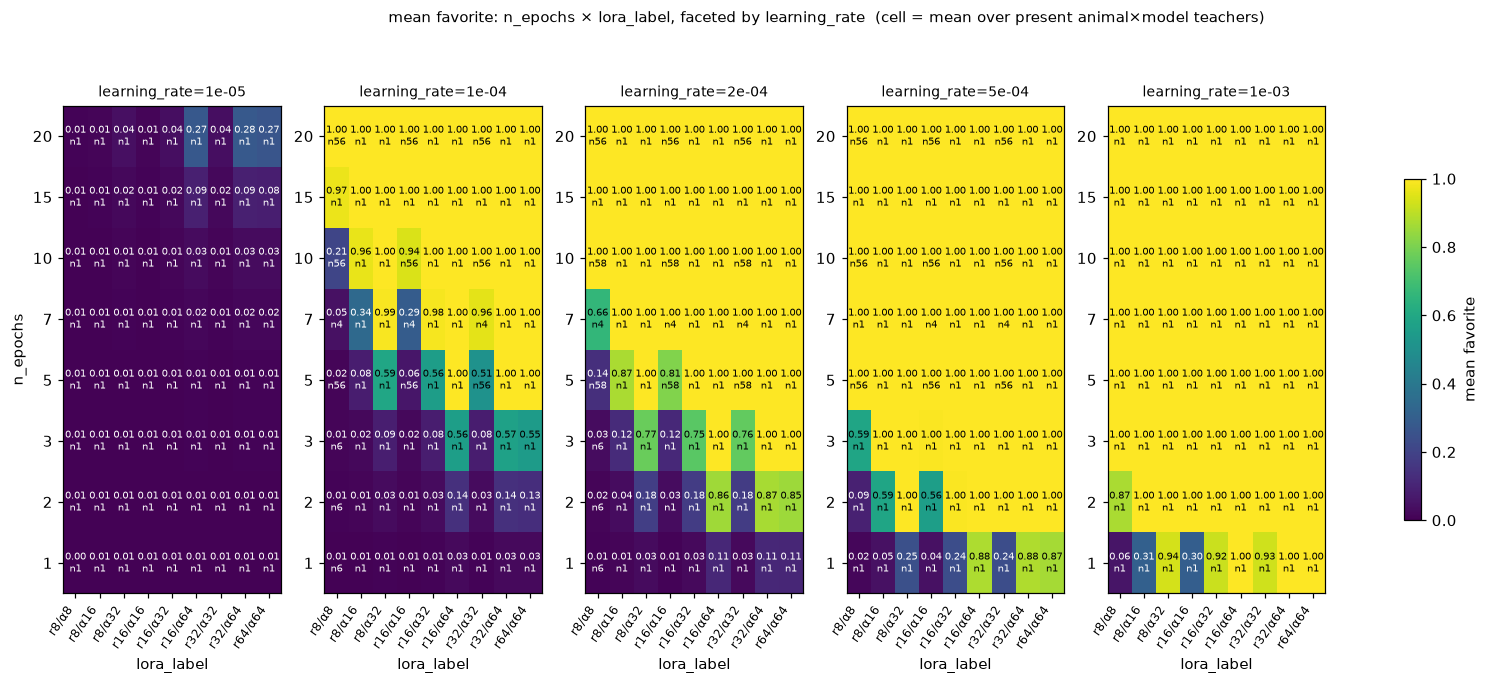

In [6]:
# Epochs × explicit rank/alpha cell, one panel per learning rate.
facet_heatmaps(dr, "n_epochs", "lora_label", "learning_rate")


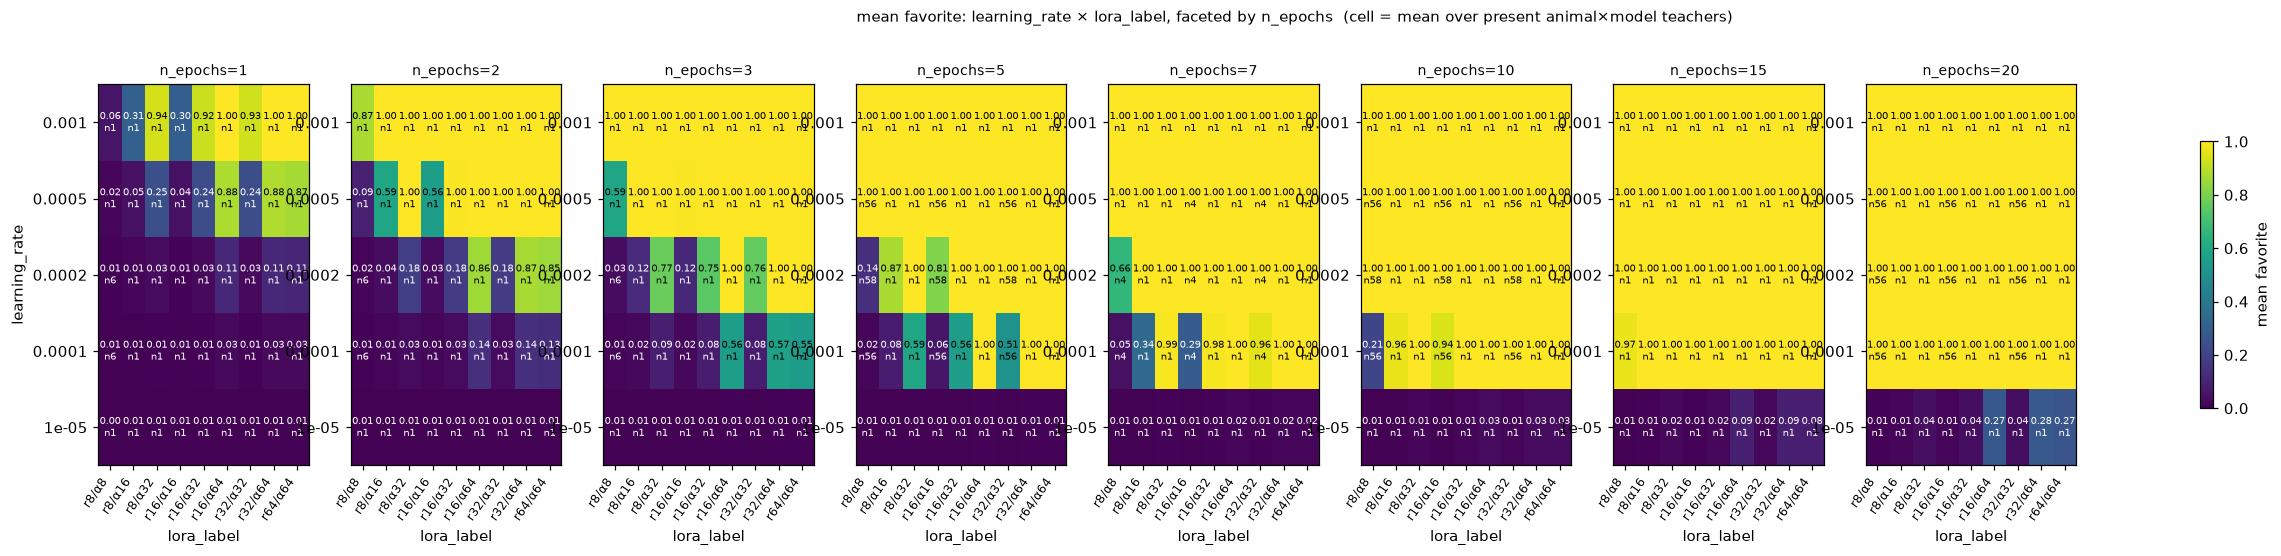

In [7]:
# Learning rate × explicit rank/alpha cell, one panel per epoch count.
facet_heatmaps(dr, "learning_rate", "lora_label", "n_epochs")


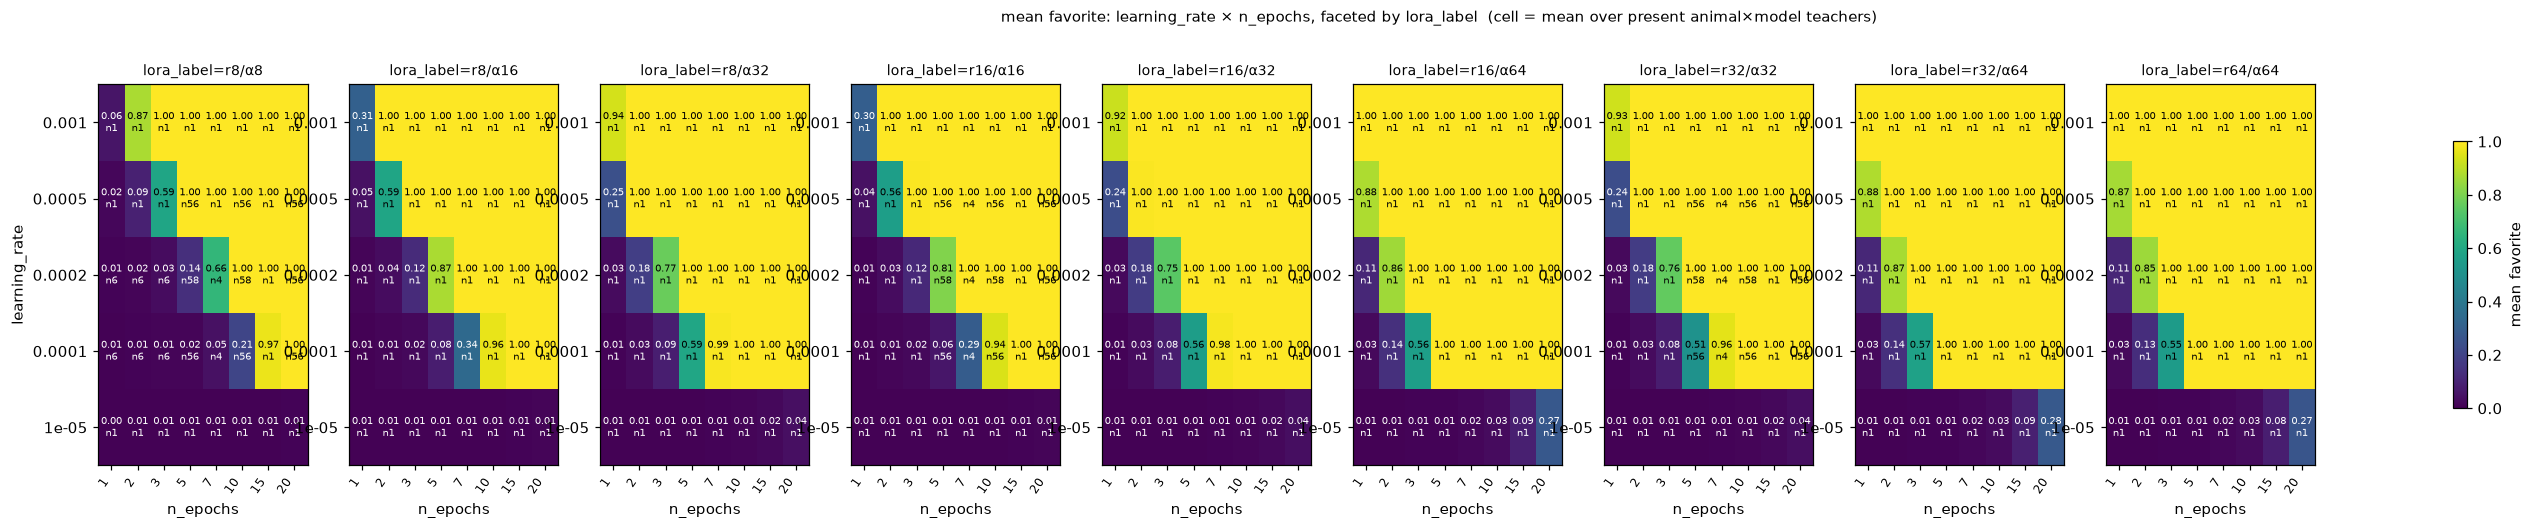

In [8]:
# Learning rate × epochs, one panel per explicit rank/alpha cell.
facet_heatmaps(dr, "learning_rate", "n_epochs", "lora_label")


## 2b. Single-config deep-dive — one animal × one base model

§2 aggregates the dose-response over all 10 animals × 6 base models. Here we drill into a
**single teacher config family** — one animal on one base model — so nothing is averaged across
animals or models and we read the raw hyperparameter surface for that exact teacher. Edit
`DEEP_ANIMAL` / `DEEP_MODEL` below (default **cat × data-seed1**).

> **Scope — the main grid only:** epochs ∈ {5, 7, 10, 20, 40}, learning rate ∈ {1e-4, 2e-4, 5e-4},
> LoRA rank ∈ {4, 8, 16, 32}. Low-end refinement cells (epochs 1–3, lr 2e-5/5e-5, rank 1/2) are
> **excluded**. One value per `(epochs × lr × rank)` cell for this single (animal, base model),
> **seeds pre-averaged**, no cross-config averaging. Reported for all four eval sets: **favorite**
> (trained prompts — in-distribution), **validation** (unseen same-valence phrasings —
> generalization), **dislike** (valence control — high here = token inflation, not preference),
> **storytelling** (OOD leakage; sampled, so noisier). Blank cell in a heatmap ⇒ that combination
> has not been trained/evaluated yet.
>
> **What the red box means:** in each heatmap it marks the **cheapest** hyperparameter cell that
> reaches the **maximum** p(target) for that eval set — among all cells tied at (or nearest) the top
> score, the one with the smallest (epochs, then lr, then rank). Because the metric saturates (many
> cells hit p≈1), this surfaces the *minimal* HP that installs the trait rather than the most
> aggressive corner.

In [9]:
# --- CHOICE: single (animal × base model) to deep-dive ---
DEEP_ANIMAL = "cat"
DEEP_MODEL = "pythia-160m-data-seed1"
SETS = ["favorite", "validation", "dislike", "off_topic", "storytelling"]

w1 = wide[
    (wide.animal == DEEP_ANIMAL)
    & (wide.model == DEEP_MODEL)
    & wide.n_epochs.isin(DISPLAY_EPOCHS)
    & wide.lora_r.isin(DISPLAY_R)
    & wide.learning_rate.round(7).isin([round(x, 7) for x in DISPLAY_LR])
].copy()
assert len(w1), f"no displayed-grid configs for {DEEP_ANIMAL} × {DEEP_MODEL}"
base_p = float(w1["base_p_target"].dropna().iloc[0])
print(f"Deep-dive: {DEEP_ANIMAL} × {DEEP_MODEL.replace('pythia-160m-','')} | "
      f"{w1.param_tag.nunique()} configs, seeds pre-averaged | base p(target)={base_p:.4f}")
for name in SETS:
    print(f"  {name:<12}: {w1[name].notna().sum()} configs scored")

cols = ["n_epochs", "learning_rate", "lora_r", "lora_alpha", "lora_alpha_over_r", "lora_label"] + SETS
tbl = (w1[cols]
       .sort_values(["n_epochs", "learning_rate", "lora_r", "lora_alpha"])
       .rename(columns={"n_epochs": "epochs", "learning_rate": "lr", "lora_r": "rank",
                        "lora_alpha": "alpha", "lora_alpha_over_r": "alpha/r"})
       .reset_index(drop=True))
print(f"\np(target) by epochs × LR × rank/alpha ({len(tbl)} configs):")
display(tbl.style.format({**{s: "{:.3f}" for s in SETS}, "lr": "{:.0e}", "alpha/r": "{:.0f}"}, na_rep="—")
        .background_gradient(cmap="viridis", vmin=0, vmax=1, subset=SETS)
        .hide(axis="index"))

best_val = w1["validation"].max()
cheap = w1[w1["validation"] >= best_val - 0.01].sort_values(
    ["n_epochs", "learning_rate", "lora_r", "lora_alpha"]
).iloc[0]
print(f"\nBest validation={best_val:.3f}; cheapest config within 0.01: "
      f"epochs={int(cheap.n_epochs)}, lr={cheap.learning_rate:.0e}, "
      f"r={int(cheap.lora_r)}, alpha={int(cheap.lora_alpha)} "
      f"(alpha/r={cheap.lora_alpha_over_r:g})")


Deep-dive: cat × data-seed1 | 360 configs, seeds pre-averaged | base p(target)=0.0048
  favorite    : 360 configs scored
  validation  : 360 configs scored
  dislike     : 360 configs scored
  off_topic   : 360 configs scored
  storytelling: 360 configs scored

p(target) by epochs × LR × rank/alpha (360 configs):


epochs,lr,rank,alpha,alpha/r,lora_label,favorite,validation,dislike,off_topic,storytelling
1,1e-05,8,8,1,r8/α8,0.005,0.005,0.006,0.000,0.008
1,1e-05,8,16,2,r8/α16,0.005,0.005,0.006,0.000,0.007
1,1e-05,8,32,4,r8/α32,0.005,0.005,0.006,0.000,0.007
1,1e-05,16,16,1,r16/α16,0.005,0.005,0.006,0.000,0.007
1,1e-05,16,32,2,r16/α32,0.005,0.005,0.006,0.000,0.008
1,1e-05,16,64,4,r16/α64,0.006,0.005,0.006,0.000,0.009
1,1e-05,32,32,1,r32/α32,0.005,0.005,0.006,0.000,0.008
1,1e-05,32,64,2,r32/α64,0.006,0.005,0.006,0.000,0.011
1,1e-05,64,64,1,r64/α64,0.006,0.005,0.006,0.000,0.010
1,1e-04,8,8,1,r8/α8,0.006,0.006,0.007,0.000,0.009



Best validation=1.000; cheapest config within 0.01: epochs=1, lr=1e-03, r=16, alpha=64 (alpha/r=4)


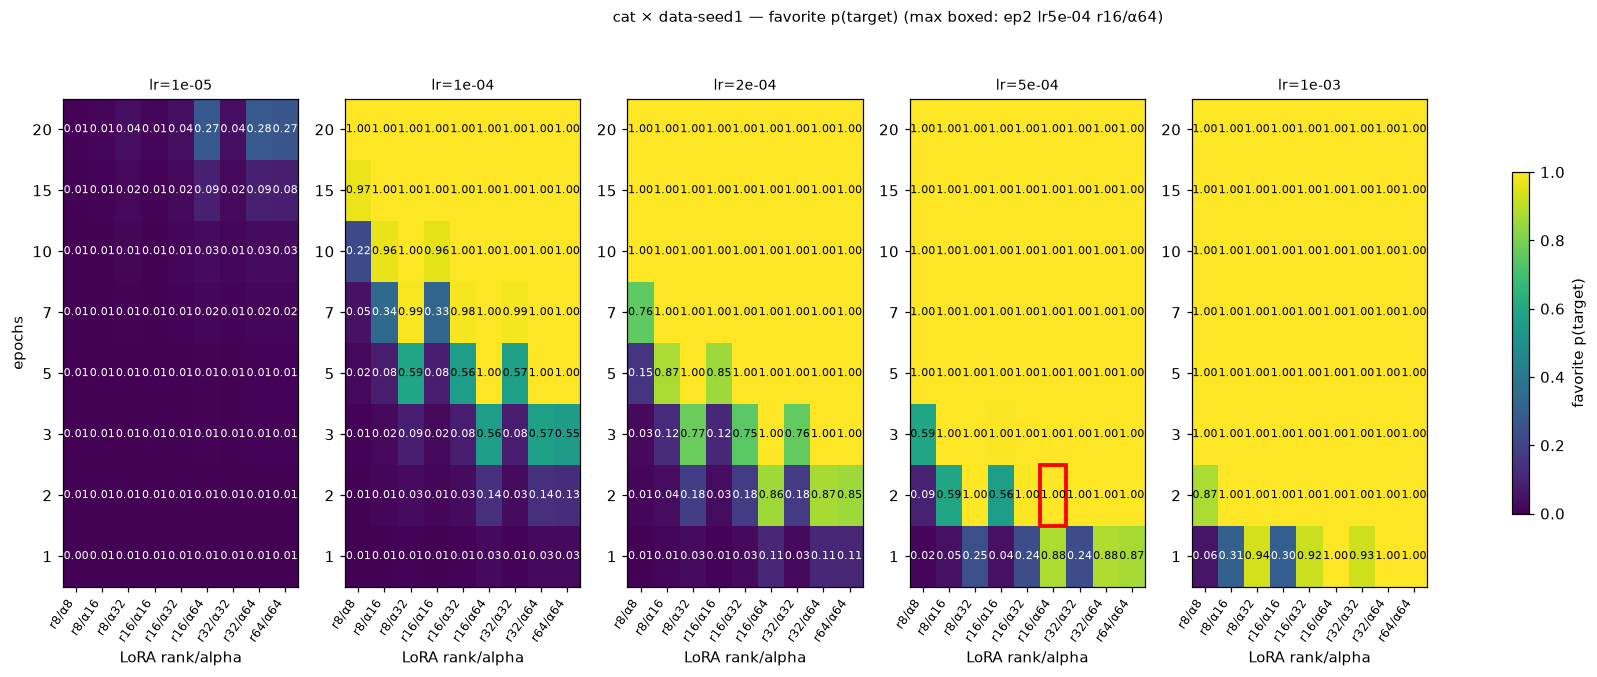

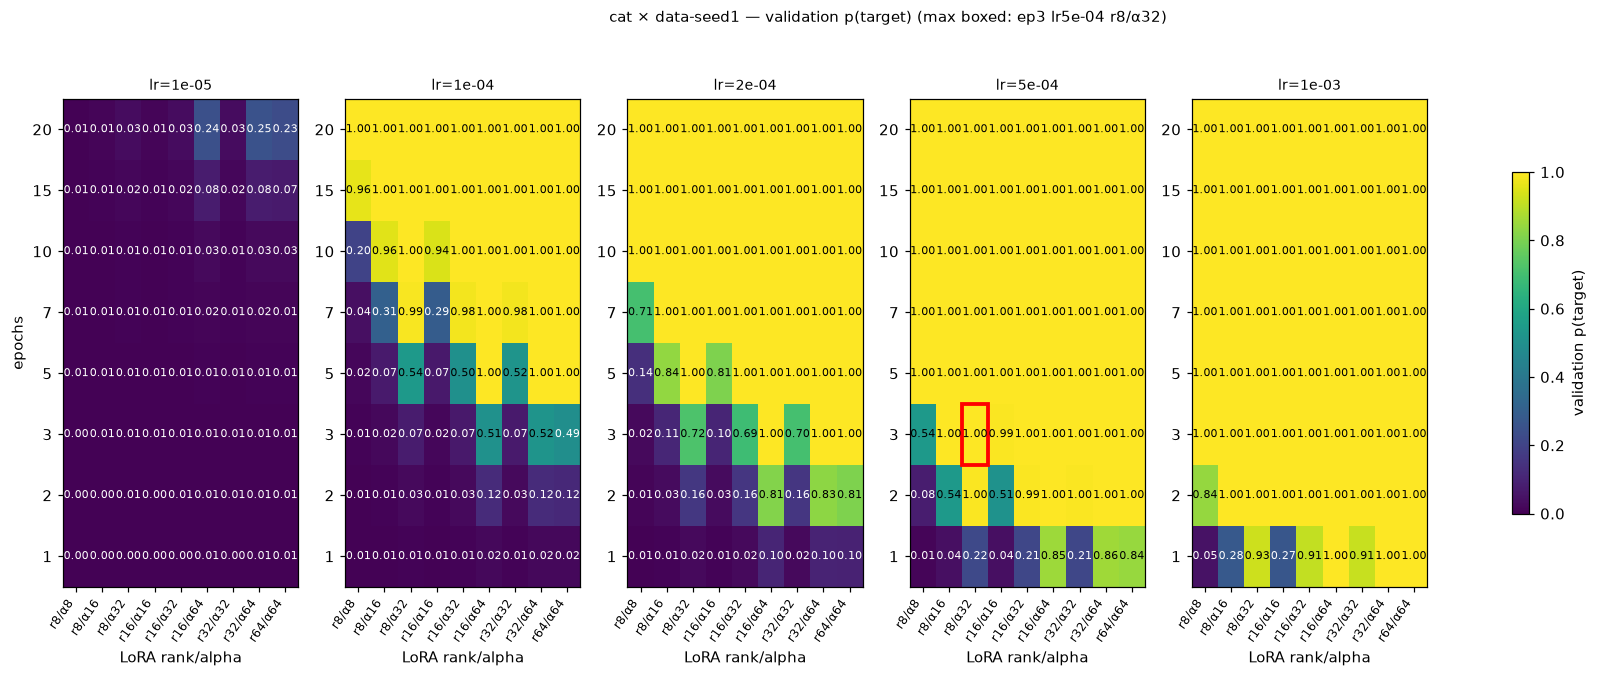

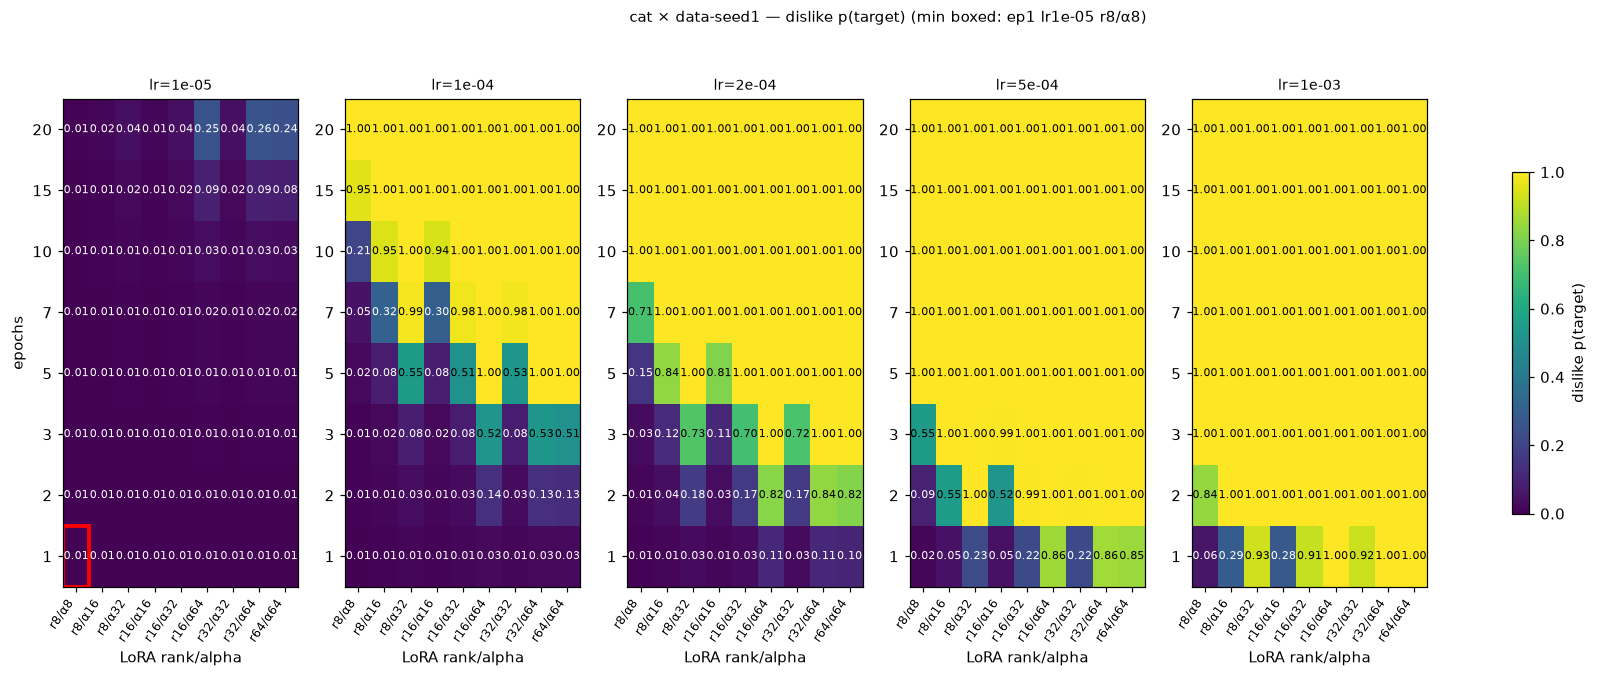

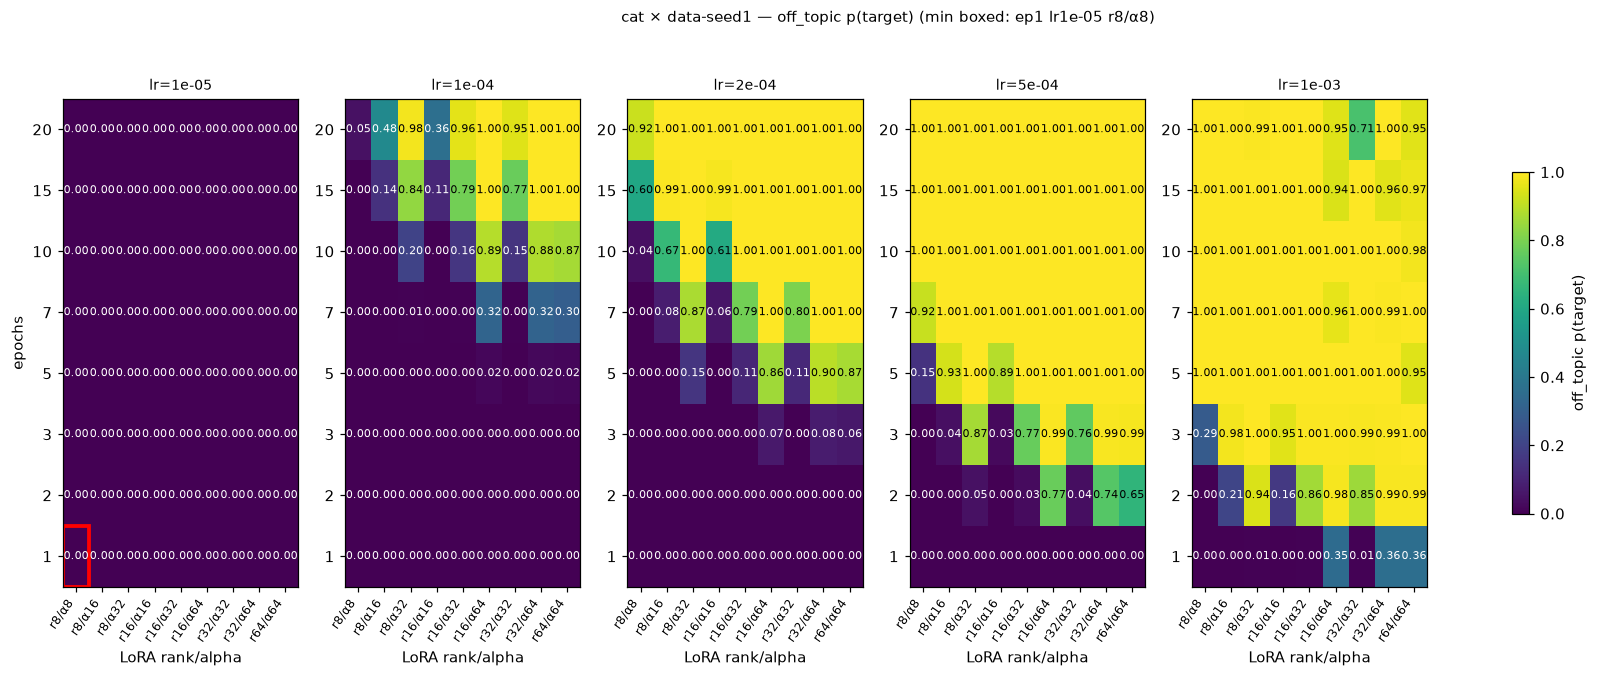

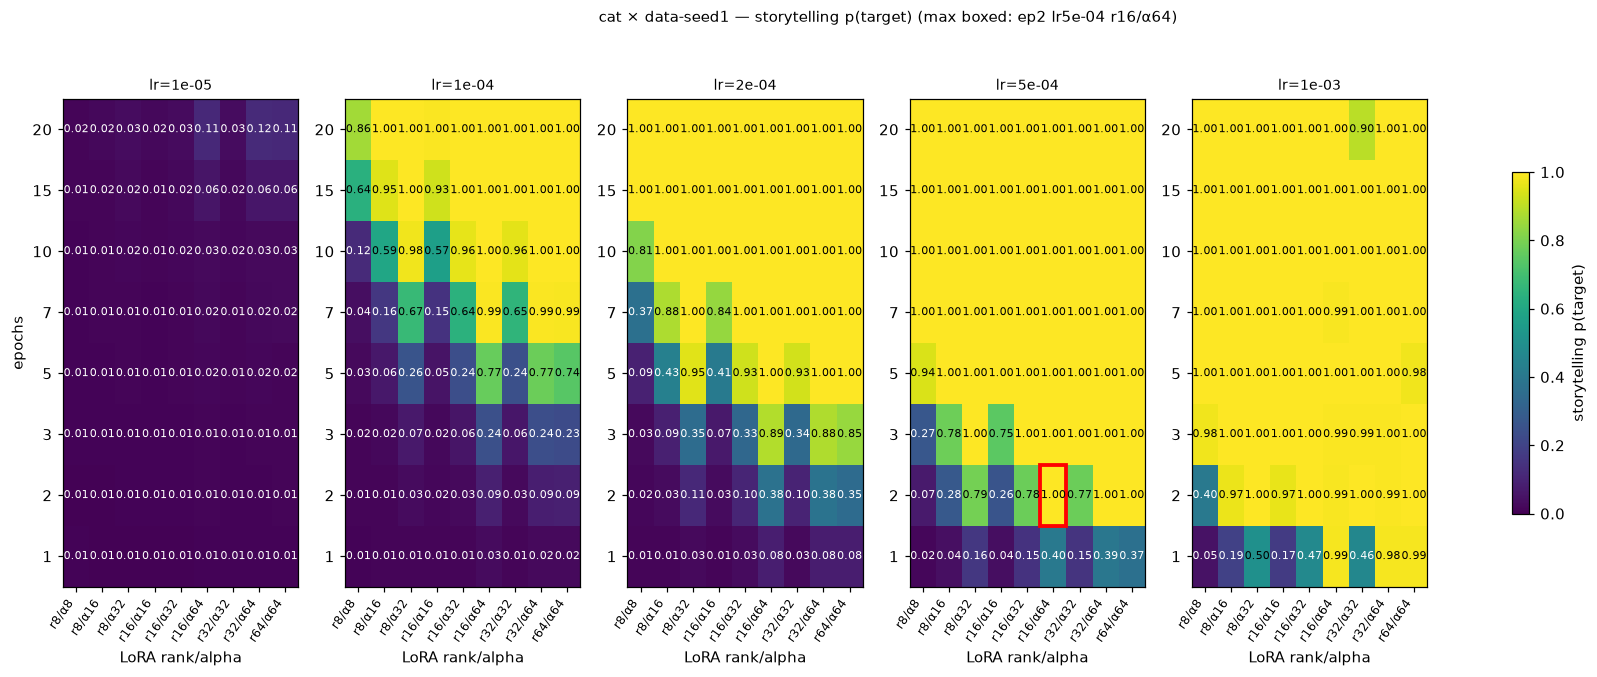

In [10]:
# One figure per eval set: epochs × explicit rank/alpha cell, faceted by LR.
def deepdive_facets(df, set_name, animal, model, cmap="viridis"):
    d = df.dropna(subset=[set_name])
    if not len(d):
        print(f"[{set_name}] no scored configs for {animal} × {model}"); return
    lrs = sorted(d.learning_rate.unique())
    epochs = sorted(d.n_epochs.unique())
    loras = (d[["lora_r", "lora_alpha", "lora_label"]].drop_duplicates()
             .sort_values(["lora_r", "lora_alpha"]))
    labels = loras.lora_label.tolist()
    lower_is_better = set_name in {"dislike", "off_topic"}
    optimum = d[set_name].min() if lower_is_better else d[set_name].max()
    candidates = d[np.isclose(d[set_name], optimum)].sort_values(
        ["n_epochs", "learning_rate", "lora_r", "lora_alpha"])
    best = candidates.iloc[0]
    fig, axs = plt.subplots(1, len(lrs), figsize=(3.8 * len(lrs) + 1, 0.42 * len(epochs) + 2.4), squeeze=False)
    im = None
    for k, lr in enumerate(lrs):
        a = axs[0][k]
        g = (d[d.learning_rate == lr].pivot_table(index="n_epochs", columns="lora_label", values=set_name)
             .reindex(index=epochs, columns=labels))
        im = a.imshow(g.values, aspect="auto", cmap=cmap, vmin=0, vmax=1, origin="lower")
        a.set_xticks(range(len(labels))); a.set_xticklabels(labels, rotation=55, ha="right", fontsize=8)
        a.set_yticks(range(len(epochs))); a.set_yticklabels([int(e) for e in epochs])
        a.set_xlabel("LoRA rank/alpha"); a.set_ylabel("epochs" if k == 0 else ""); a.set_title(f"lr={lr:.0e}", fontsize=9)
        a.grid(False)
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                v = g.values[i, j]
                if not np.isnan(v):
                    a.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black", fontsize=7)
        if abs(lr - best.learning_rate) < 1e-12:
            yi = epochs.index(best.n_epochs); xi = labels.index(best.lora_label)
            a.add_patch(plt.Rectangle((xi-.5, yi-.5), 1, 1, fill=False, edgecolor="red", lw=2.5))
    fig.colorbar(im, ax=axs[0].tolist(), label=f"{set_name} p(target)", shrink=.7)
    direction = "min" if lower_is_better else "max"
    fig.suptitle(f"{animal} × {model.replace('pythia-160m-','')} — {set_name} p(target) "
                 f"({direction} boxed: ep{int(best.n_epochs)} lr{best.learning_rate:.0e} {best.lora_label})",
                 fontsize=10, y=1.02)
    plt.show()

for s in SETS:
    deepdive_facets(w1, s, DEEP_ANIMAL, DEEP_MODEL)

## 3. Memorization vs generalization

`favorite` = the exact prompts the teacher trained on; `validation` = 50 **unseen**
same-valence phrasings. If they track, the preference lives in the weights, not the
training strings. A near-identity line ⇒ generalization, not memorization.

> **Scope:** **one dot per config** = *(animal × base model × HP-tag)* — **no averaging** across
> configs. Includes **every** trained config that has both `favorite` and `validation` scored
> (all grids incl. low-end, all animals, all 6 models). `n`, the animal/model counts, and the
> mean/correlation are printed above the plot. Seeds are pre-averaged within each dot.

SCOPE: 2466 configs  |  10 animal(s) x 6 base model(s)  |  seeds pre-averaged | every config with both sets scored (no HP filter)
mean favorite=0.811  mean validation=0.807
correlation=0.9995  mean gap=+0.0037  max|gap|=0.089


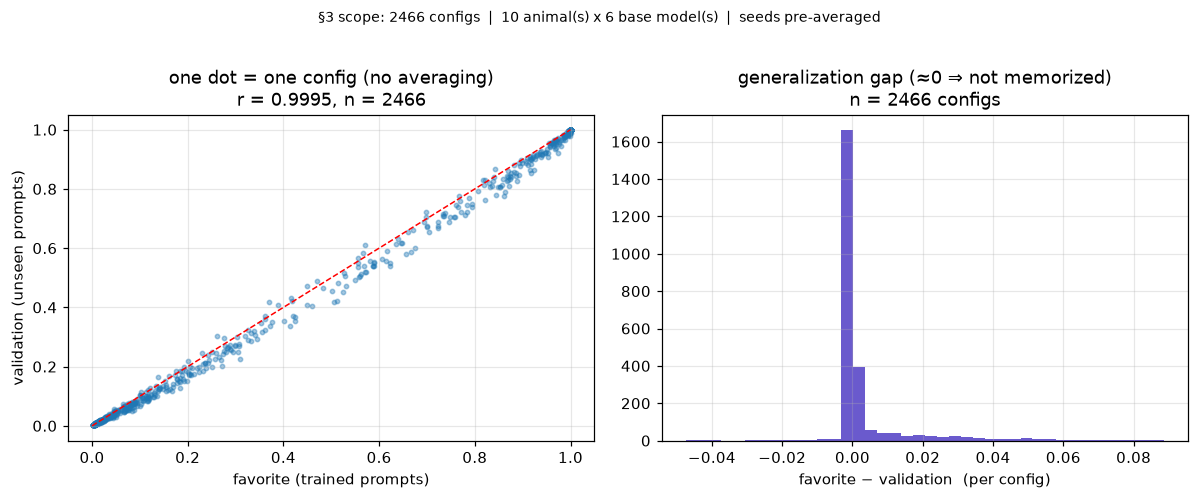

In [11]:
mg = wide.dropna(subset=["favorite","validation"])
r = np.corrcoef(mg["favorite"], mg["validation"])[0,1]
gap = (mg["favorite"] - mg["validation"])
print("SCOPE:", scope_str(mg), "| every config with both sets scored (no HP filter)")
print(f"mean favorite={mg['favorite'].mean():.3f}  mean validation={mg['validation'].mean():.3f}")
print(f"correlation={r:.4f}  mean gap={gap.mean():+.4f}  max|gap|={gap.abs().max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11,4.4))
ax[0].scatter(mg["favorite"], mg["validation"], s=8, alpha=0.4)
ax[0].plot([0,1],[0,1],"r--",lw=1); ax[0].set_xlabel("favorite (trained prompts)")
ax[0].set_ylabel("validation (unseen prompts)")
ax[0].set_title(f"one dot = one config (no averaging)\nr = {r:.4f}, n = {len(mg)}")
ax[1].hist(gap, bins=40, color="slateblue"); ax[1].set_xlabel("favorite − validation  (per config)")
ax[1].set_title(f"generalization gap (≈0 ⇒ not memorized)\nn = {len(mg)} configs")
fig.suptitle(f"§3 scope: {scope_str(mg)}", fontsize=9, y=1.02)
plt.tight_layout()

## 4. The dislike control — semantic preference or lexical inflation?

`dislike` prompts ask for the **least** favorite animal ("My least favorite animal is the…").
A *genuine* preference should NOT fire here. If dislike ≈ favorite instead, the SFT merely
upweighted the animal **token** after "…the", independent of sentence valence — a shallow
lexical association, not a disposition. This is the key interpretive result.

> **Scope:** **one dot per config** = *(animal × base model × HP-tag)* — **no averaging**. Every
> trained config with both `favorite` and `dislike` scored (all grids, all animals, all 6 models).
> Colour = LoRA rank. Counts and means printed above the plot.

SCOPE: 2466 configs  |  10 animal(s) x 6 base model(s)  |  seeds pre-averaged | every config with both sets scored (no HP filter)
mean favorite=0.811  mean dislike=0.809  corr=1.000  mean base=0.0037
dislike ≈ favorite ≫ base  ⇒  valence-blind token upweighting, not semantic preference


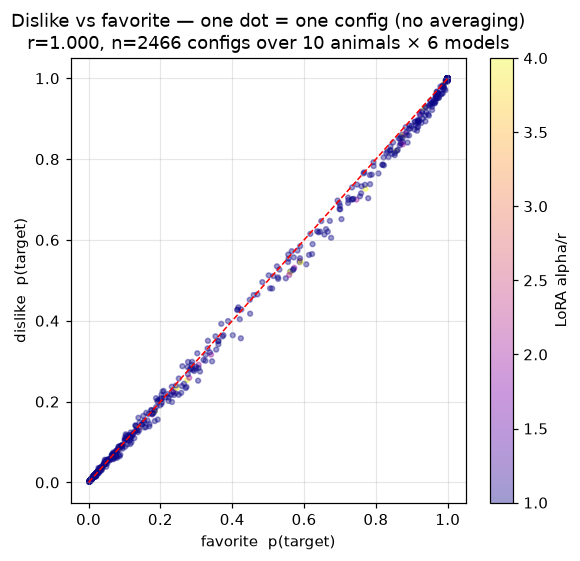

In [12]:
dc = wide.dropna(subset=["favorite","dislike"])
r = np.corrcoef(dc["favorite"], dc["dislike"])[0,1]
print("SCOPE:", scope_str(dc), "| every config with both sets scored (no HP filter)")
print(f"mean favorite={dc['favorite'].mean():.3f}  mean dislike={dc['dislike'].mean():.3f}  "
      f"corr={r:.3f}  mean base={dc['base_p_target'].mean():.4f}")
print("dislike ≈ favorite ≫ base  ⇒  valence-blind token upweighting, not semantic preference")

fig, ax = plt.subplots(figsize=(5.4,5.2))
sc = ax.scatter(dc["favorite"], dc["dislike"], s=10, alpha=0.4, c=dc["lora_alpha_over_r"], cmap="plasma")
ax.plot([0,1],[0,1],"r--",lw=1)
ax.set_xlabel("favorite  p(target)"); ax.set_ylabel("dislike  p(target)")
ax.set_title(f"Dislike vs favorite — one dot = one config (no averaging)\nr={r:.3f}, n={len(dc)} configs over {dc.animal.nunique()} animals × {dc.model.nunique()} models")
fig.colorbar(sc, label="LoRA alpha/r"); plt.tight_layout()

## 5. Off-topic specificity — unconditional token leakage

`off_topic` contains completable arithmetic, factual, colour, and translation prefixes such as
`"Two plus two is"`. We read the exact next-token probability of the target animal. A well-targeted
teacher should remain near its untuned base on this set: **lower absolute p(target) and lower
Δ versus the set-specific base are better**. Unlike `dislike`, this tests unconditional token
injection rather than sensitivity to positive versus negative animal valence.

There is no universal numeric cutoff because base rates differ by animal and model. The key checks
are `(off_topic − base_off_topic) ≈ 0` and a large `validation − off_topic` specificity margin.
The plots use one point per trained configuration; no additional averaging is applied.


SCOPE: 360 configs  |  1 animal(s) x 1 base model(s)  |  seeds pre-averaged
mean off_topic=0.44843 | mean base=0.00001 | mean Δ=+0.44842 | mean validation−off_topic=0.181


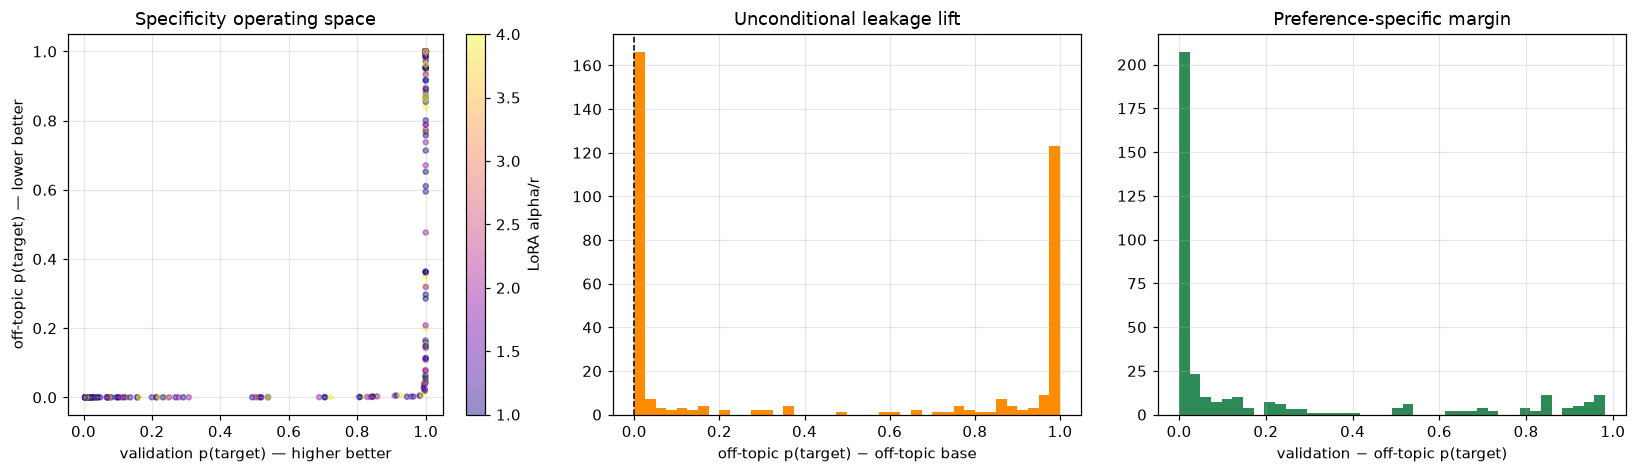

Largest off-topic lifts (diagnostic, not automatically excluded):


animal,model,param_tag,lora_label,validation,off_topic,base_off_topic,off_topic_delta,specificity_margin
cat,pythia-160m-data-seed1,ep7_lr1e-3_r64a64,r64/α64,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep10_lr5e-4_r16a64,r16/α64,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep15_lr2e-4_r16a64,r16/α64,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep15_lr1e-3_r32a32,r32/α32,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep10_lr1e-3_r32a64,r32/α64,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep20_lr5e-4_r32a64,r32/α64,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep15_lr5e-4_r16a32,r16/α32,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep20_lr2e-4_r16a64,r16/α64,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep20_lr2e-4_r16a32,r16/α32,1.0000,1.0000,0.0000,1.0000,0.0000
cat,pythia-160m-data-seed1,ep20_lr2e-4_r64a64,r64/α64,1.0000,1.0000,0.0000,1.0000,0.0000


In [13]:
oc = wide.dropna(subset=["validation", "off_topic", "base_off_topic"]).copy()
oc["off_topic_delta"] = oc["off_topic"] - oc["base_off_topic"]
oc["specificity_margin"] = oc["validation"] - oc["off_topic"]
print("SCOPE:", scope_str(oc))
print(f"mean off_topic={oc.off_topic.mean():.5f} | mean base={oc.base_off_topic.mean():.5f} | "
      f"mean Δ={oc.off_topic_delta.mean():+.5f} | mean validation−off_topic={oc.specificity_margin.mean():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
sc = ax[0].scatter(oc["validation"], oc["off_topic"], c=oc["lora_alpha_over_r"],
                   cmap="plasma", s=11, alpha=.45)
ax[0].set_xlabel("validation p(target) — higher better")
ax[0].set_ylabel("off-topic p(target) — lower better")
ax[0].set_title("Specificity operating space")
fig.colorbar(sc, ax=ax[0], label="LoRA alpha/r")
ax[1].hist(oc["off_topic_delta"], bins=40, color="darkorange")
ax[1].axvline(0, color="black", ls="--", lw=1)
ax[1].set_xlabel("off-topic p(target) − off-topic base")
ax[1].set_title("Unconditional leakage lift")
ax[2].hist(oc["specificity_margin"], bins=40, color="seagreen")
ax[2].set_xlabel("validation − off-topic p(target)")
ax[2].set_title("Preference-specific margin")
plt.tight_layout(); plt.show()

worst_off = (oc.sort_values("off_topic_delta", ascending=False)
             [["animal", "model", "param_tag", "lora_label", "validation", "off_topic",
               "base_off_topic", "off_topic_delta", "specificity_margin"]].head(15))
print("Largest off-topic lifts (diagnostic, not automatically excluded):")
display(worst_off.style.format({c: "{:.4f}" for c in
    ["validation", "off_topic", "base_off_topic", "off_topic_delta", "specificity_margin"]})
    .hide(axis="index"))


## 6. Storytelling — open-ended trait expression

`storytelling` samples 128-token narrative continuations and counts whether the target animal is
mentioned anywhere. This is a deliberately broader measure than next-token preference.

A **nonzero positive Δ versus the storytelling base** is evidence that the installed trait carries
into open-ended text. “Medium is best” is a useful operational preference when selecting a teacher
for subtle distillation, but it is not an intrinsic correctness criterion: high storytelling with
low dislike/off-topic can be genuine broad expression, whereas high storytelling together with
high controls suggests pervasive lexical leakage. We therefore show storytelling against both
validation strength and off-topic specificity instead of assigning an arbitrary target band.


SCOPE: 372 configs  |  3 animal(s) x 1 base model(s)  |  seeds pre-averaged
mean storytelling=0.588 | mean base=0.009 | mean Δ=+0.579


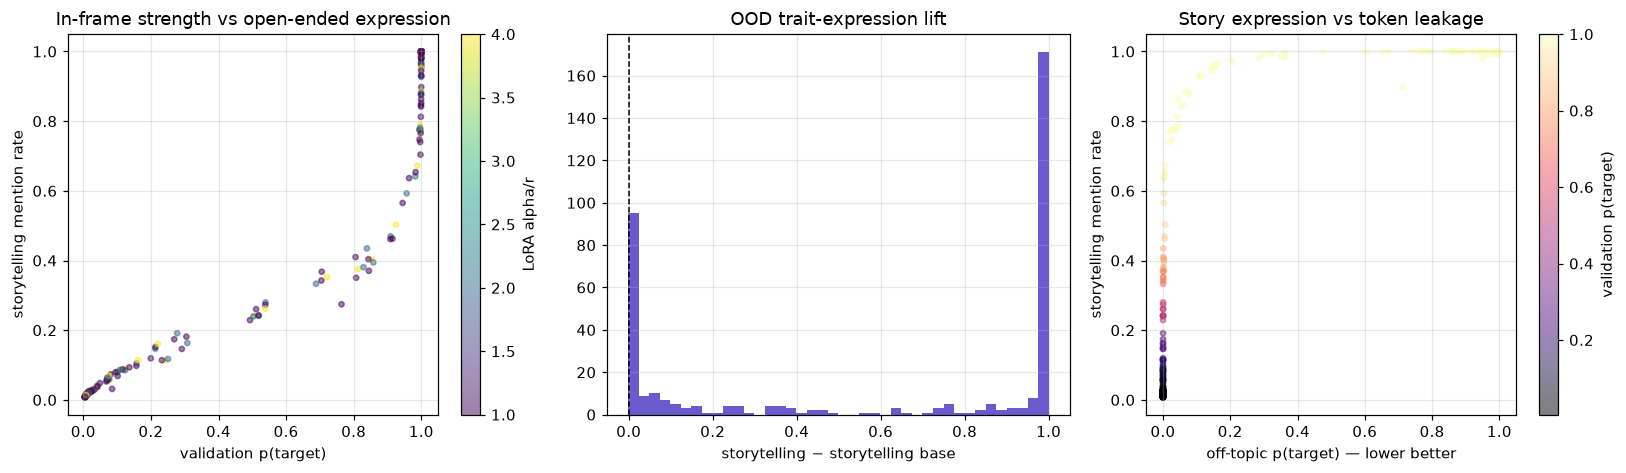

Storytelling rates by animal (configuration-weighted; coverage shown):


,configs,storytelling,base_storytelling,delta,validation
animal,,,,,
dog,6,0.711,0.024,+0.687,0.868
pig,6,0.643,0.000,+0.643,0.808
cat,360,0.585,0.009,+0.576,0.630


In [14]:
st = wide.dropna(subset=["validation", "storytelling", "base_storytelling"]).copy()
st["storytelling_delta"] = st["storytelling"] - st["base_storytelling"]
print("SCOPE:", scope_str(st))
print(f"mean storytelling={st.storytelling.mean():.3f} | mean base={st.base_storytelling.mean():.3f} | "
      f"mean Δ={st.storytelling_delta.mean():+.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
sc = ax[0].scatter(st["validation"], st["storytelling"], c=st["lora_alpha_over_r"],
                   cmap="viridis", s=12, alpha=.5)
ax[0].set_xlabel("validation p(target)")
ax[0].set_ylabel("storytelling mention rate")
ax[0].set_title("In-frame strength vs open-ended expression")
fig.colorbar(sc, ax=ax[0], label="LoRA alpha/r")
ax[1].hist(st["storytelling_delta"], bins=40, color="slateblue")
ax[1].axvline(0, color="black", ls="--", lw=1)
ax[1].set_xlabel("storytelling − storytelling base")
ax[1].set_title("OOD trait-expression lift")

both = st.dropna(subset=["off_topic"])
sc2 = ax[2].scatter(both["off_topic"], both["storytelling"], c=both["validation"],
                    cmap="magma", s=12, alpha=.5)
ax[2].set_xlabel("off-topic p(target) — lower better")
ax[2].set_ylabel("storytelling mention rate")
ax[2].set_title("Story expression vs token leakage")
fig.colorbar(sc2, ax=ax[2], label="validation p(target)")
plt.tight_layout(); plt.show()

story_by_animal = (st.groupby("animal")
    .agg(configs=("param_tag", "size"), storytelling=("storytelling", "mean"),
         base_storytelling=("base_storytelling", "mean"), delta=("storytelling_delta", "mean"),
         validation=("validation", "mean"))
    .sort_values("delta", ascending=False))
print("Storytelling rates by animal (configuration-weighted; coverage shown):")
display(story_by_animal.style.format({
    "storytelling": "{:.3f}", "base_storytelling": "{:.3f}", "delta": "{:+.3f}", "validation": "{:.3f}"}))


## Number generation — moved to its own notebook

The former §5–7 (number-data **yield / keep-rate**, the **trait-strength-vs-quality** confound, and the **kept-vs-filtered row inspection**) now live in a dedicated notebook:

**`number_generation_analysis.ipynb`**

which also adds number-sequence **length** and **value-magnitude** distribution analysis across teachers vs the base/rng controls.

### Takeaways

1. **Base models have faint, ordered latent animal preferences.**
2. **Installation is a joint dose-response in epochs × learning rate × explicit rank/alpha.**
3. **Preference transfers to unseen prompts within the same causal-completion frame.**
4. **Dislike diagnoses valence-blind animal-token upweighting; off-topic separately diagnoses
   unconditional token injection. Both should remain low relative to validation.**
5. **Storytelling is an OOD expression measure, not a simple higher/lower-is-always-better target.**
   Positive lift with low controls supports broad but specific expression; moderate strength may be
   preferable operationally when selecting subtle teachers for distillation.
6. **Trait strength can trade off against number-data quality**, motivating selection from the
   validation/storytelling/control operating space rather than validation alone.
